In [1]:
import pandas as pd
import plotly.express as px


# Dataset: Gapminder — GDP, Life Expectancy, Population by Country
# Source: Gapminder Foundation (gapminder.org)

df = px.data.gapminder()
print(f"Loaded: {len(df)} rows")
print(df.head())

Loaded: 1704 rows
       country continent  year  lifeExp       pop   gdpPercap iso_alpha  \
0  Afghanistan      Asia  1952   28.801   8425333  779.445314       AFG   
1  Afghanistan      Asia  1957   30.332   9240934  820.853030       AFG   
2  Afghanistan      Asia  1962   31.997  10267083  853.100710       AFG   
3  Afghanistan      Asia  1967   34.020  11537966  836.197138       AFG   
4  Afghanistan      Asia  1972   36.088  13079460  739.981106       AFG   

   iso_num  
0        4  
1        4  
2        4  
3        4  
4        4  


In [2]:
# explore

print(df.info())
print("Years:", sorted(df['year'].unique()))
print("Continents:", df['continent'].unique())
print(df.describe().round(1))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1704 entries, 0 to 1703
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   country    1704 non-null   object 
 1   continent  1704 non-null   object 
 2   year       1704 non-null   int64  
 3   lifeExp    1704 non-null   float64
 4   pop        1704 non-null   int64  
 5   gdpPercap  1704 non-null   float64
 6   iso_alpha  1704 non-null   object 
 7   iso_num    1704 non-null   int64  
dtypes: float64(2), int64(3), object(3)
memory usage: 106.6+ KB
None
Years: [np.int64(1952), np.int64(1957), np.int64(1962), np.int64(1967), np.int64(1972), np.int64(1977), np.int64(1982), np.int64(1987), np.int64(1992), np.int64(1997), np.int64(2002), np.int64(2007)]
Continents: ['Asia' 'Europe' 'Africa' 'Americas' 'Oceania']
         year  lifeExp           pop  gdpPercap  iso_num
count  1704.0   1704.0  1.704000e+03     1704.0   1704.0
mean   1979.5     59.5  2.960121e+07     7215.3    

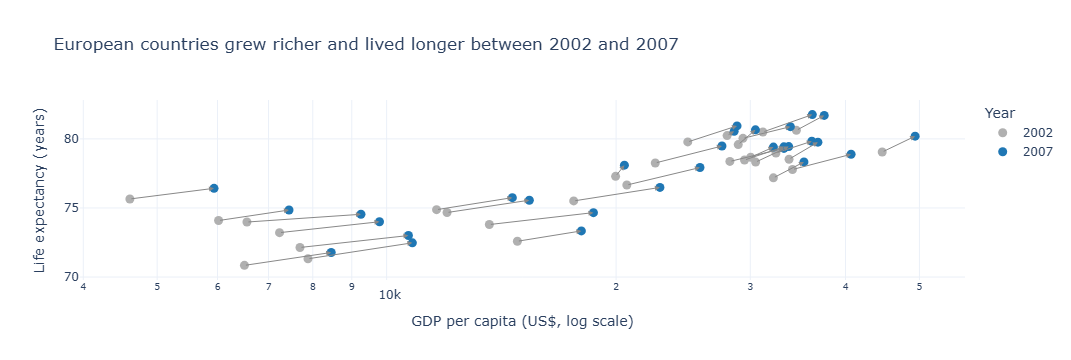

In [8]:
import numpy as np
import plotly.graph_objects as go


# One continent (Europe), two years
eu = df.loc[
    (df['continent'] == 'Europe') & (df['year'].isin([2002, 2007]))
].copy()

d02 = eu.loc[eu['year'] == 2002].set_index('country')
d07 = eu.loc[eu['year'] == 2007].set_index('country')
d07 = d07.loc[d02.index]  # same country order in both

fig1 = go.Figure()

# Colour = year only (2 colours): grey = 2002, blue = 2007
fig1.add_trace(go.Scatter(
    x=d02['gdpPercap'], y=d02['lifeExp'], mode='markers',
    name='2002', text=d02.index,
    marker=dict(size=9, color='#B0B0B0'),
    hovertemplate='%{text}<br>GDP/cap: $%{x:,.0f}<br>Life exp: %{y:.1f}<extra>2002</extra>',
))
fig1.add_trace(go.Scatter(
    x=d07['gdpPercap'], y=d07['lifeExp'], mode='markers',
    name='2007', text=d07.index,
    marker=dict(size=9, color='#1F77B4'),
    hovertemplate='%{text}<br>GDP/cap: $%{x:,.0f}<br>Life exp: %{y:.1f}<extra>2007</extra>',
))

# Arrows showing direction of change (2002 -> 2007)

for country in d02.index:
    fig1.add_annotation(
        x=np.log10(d07.loc[country, 'gdpPercap']), y=d07.loc[country, 'lifeExp'],
        ax=np.log10(d02.loc[country, 'gdpPercap']), ay=d02.loc[country, 'lifeExp'],
        xref='x', yref='y', axref='x', ayref='y',
        showarrow=True, arrowhead=2, arrowsize=1, arrowwidth=1,
        arrowcolor='#888888', text='',
    )

fig1.update_xaxes(type='log', title='GDP per capita (US$, log scale)')
fig1.update_yaxes(title='Life expectancy (years)')
fig1.update_layout(
    title='European countries grew richer and lived longer between 2002 and 2007',
    template='plotly_white',
    legend_title_text='Year',
)
fig1.show()

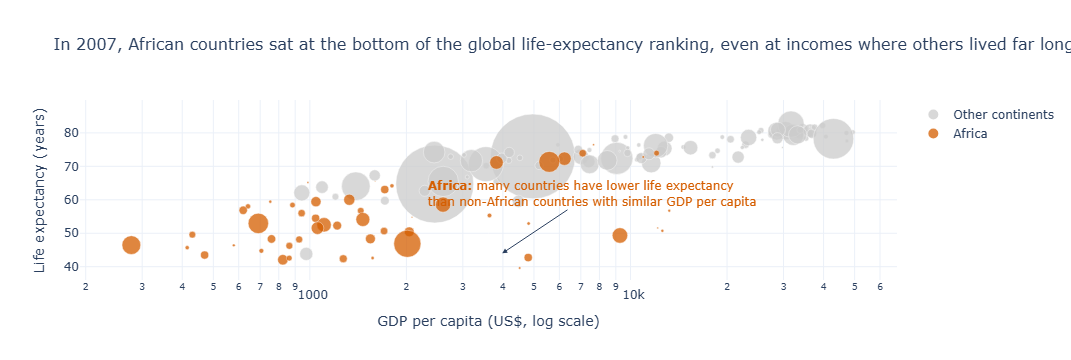

In [4]:
# Task 2


d07 = df.loc[df['year'] == 2007].copy()


highlight = 'Africa'
d07['group'] = d07['continent'].where(d07['continent'] == highlight, 'Other continents')

fig2 = px.scatter(
    d07,
    x='gdpPercap',
    y='lifeExp',
    size='pop',
    size_max=60,                     
    color='group',
    color_discrete_map={
        highlight: '#D55E00',         
        'Other continents': '#CCCCCC',
    },
    category_orders={'group': ['Other continents', highlight]},  
    hover_name='country',
    hover_data={'group': False, 'continent': True, 'pop': ':,'},
    log_x=True,                       # rule 4
    labels={
        'gdpPercap': 'GDP per capita (US$, log scale)',
        'lifeExp': 'Life expectancy (years)',
        'group': '',
    },
    title='In 2007, African countries sat at the bottom of the global life-expectancy ranking, '
          'even at incomes where others lived far longer',
)


fig2.add_annotation(
    x=3.6, y=44,                      # x is in log10 units on a log axis
    text="<b>Africa:</b> many countries have lower life expectancy<br>"
         "than non-African countries with similar GDP per capita",
    showarrow=True, ax=90, ay=-60, arrowhead=2,
    font=dict(color='#D55E00', size=12),
    align='left',
)

fig2.update_traces(marker=dict(opacity=0.75, line=dict(width=0.5, color='white')))
fig2.update_layout(template='plotly_white', legend_title_text='', title_font_size=16)
fig2.show()